# 📊 Fraud Detection Analysis - Detailed

## Healthcare Claims Fraud Statistical Analysis

This notebook provides comprehensive statistical analysis of fraudulent vs legitimate healthcare claims.

**Analysis includes:**
- Dataset overview and structure
- Fraud distribution analysis
- Financial comparison by fraud status
- Claim type breakdown
- Correlation analysis with fraud
- Statistical significance testing (T-tests)
- Interactive visualizations
- Detailed statistical reports
- Export of fraudulent claims for review

## Step 0: Import Libraries

In [22]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
colors = {'legitimate': '#1D9E75', 'fraudulent': '#E85D24'}

print('✓ All libraries imported successfully!')

✓ All libraries imported successfully!


## Step 1: Load Dataset

In [23]:
# Load the fraud-labeled data
df = pd.read_csv('d:/SecureHIC/src/outputs/cms_fhir_with_fraud_target_from_code.csv')

print(f'✓ Dataset loaded successfully!')
print(f'  Shape: {df.shape}')
print(f'  Memory: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')
print(f'\nFirst few rows:')
df.head()

✓ Dataset loaded successfully!
  Shape: (4000, 29)
  Memory: 2.44 MB

First few rows:


,secure_patient_id,claim_type,insurance_status,coverage_start,coverage_end,payment_amount,total_charged,total_line_items,num_diagnosis_codes,num_procedure_codes,...,line_benefit_total,line_paid_to_provider_total,line_paid_to_patient_total,line_deductible_total,line_coinsurance_total,line_priorpayer_total,line_all_adjudication_total,service_duration_days,outcome,is_fraud
0,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,2003-04-29,NaN,NaN,16.95,1,0,1,...,13.56,0.0,0.0,0.0,5938.75,0.0,5972.65,0,complete,0
1,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,2003-04-29,NaN,NaN,16.95,1,0,1,...,13.56,0.0,0.0,0.0,5938.75,0.0,5972.65,0,complete,0
2,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,NaN,NaN,NaN,16.95,1,0,1,...,13.56,0.0,0.0,0.0,5938.75,0.0,5972.65,0,complete,0
3,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,NaN,NaN,NaN,16.95,1,0,1,...,13.56,0.0,0.0,0.0,5938.75,0.0,5972.65,0,complete,0
4,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,NaN,NaN,NaN,44.17,1,0,1,...,35.34,0.0,0.0,0.0,222.55,0.0,310.89,0,complete,0


## Step 2: Dataset Overview

In [24]:
print("="*80)
print("DATASET OVERVIEW")
print("="*80)

print(f'\nTotal records: {len(df):,}')
print(f'Total columns: {len(df.columns)}')
print(f'Shape: {df.shape}')

print('\nColumn Details:')
print('{:<35} {:<12} {:<10} {:<10}'.format('Column', 'Type', 'Missing', 'Unique'))
print("-" * 70)

for col in df.columns:
    dtype = str(df[col].dtype)
    missing = df[col].isnull().sum()
    unique = df[col].nunique()
    print(f'{col:<35} {dtype:<12} {missing:<10} {unique:<10}')

DATASET OVERVIEW

Total records: 4,000
Total columns: 29
Shape: (4000, 29)

Column Details:
Column                              Type         Missing    Unique    
----------------------------------------------------------------------
secure_patient_id                   object       0          4         
claim_type                          object       0          7         
insurance_status                    object       0          1         
coverage_start                      object       1683       5         
coverage_end                        object       3683       2         
payment_amount                      float64      2508       246       
total_charged                       float64      0          480       
total_line_items                    int64        0          22        
num_diagnosis_codes                 int64        0          18        
num_procedure_codes                 int64        0          17        
service_category_count              int64        0      

## Step 3: Fraud Target Distribution

FRAUD TARGET DISTRIBUTION

Fraud distribution:
  Legitimate (0):  3,950 ( 98.75%) ✓
  Fraudulent (1):     50 (  1.25%) ⚠️


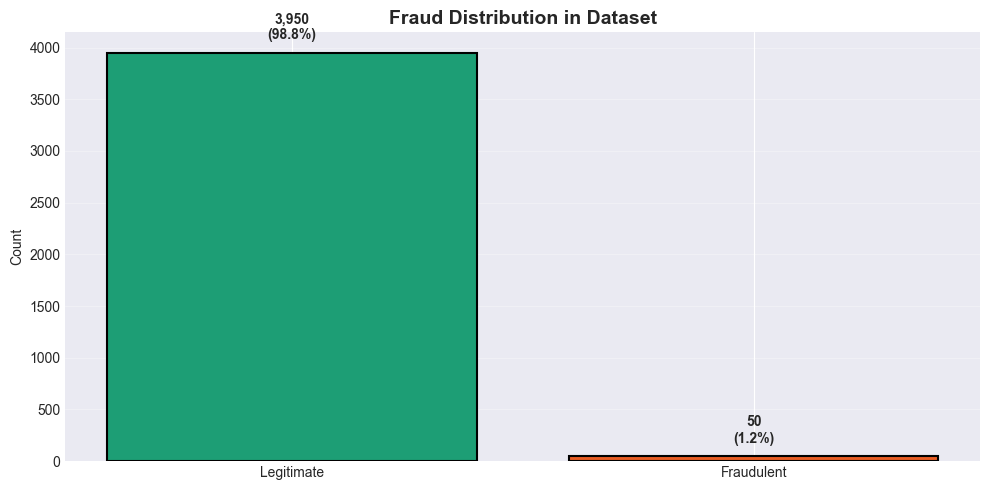

In [25]:
print("="*80)
print("FRAUD TARGET DISTRIBUTION")
print("="*80)

fraud_counts = df['is_fraud'].value_counts().sort_index()
legit_count = fraud_counts.get(0, 0)
fraud_count = fraud_counts.get(1, 0)

print(f'\nFraud distribution:')
print(f'  Legitimate (0): {legit_count:>6,} ({legit_count/len(df)*100:>6.2f}%) ✓')
print(f'  Fraudulent (1): {fraud_count:>6,} ({fraud_count/len(df)*100:>6.2f}%) ⚠️')

# Visualization
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(['Legitimate', 'Fraudulent'], 
              [legit_count, fraud_count], 
              color=[colors['legitimate'], colors['fraudulent']],
              edgecolor='black',
              linewidth=1.5)

ax.set_title('Fraud Distribution in Dataset', fontsize=14, fontweight='bold')
ax.set_ylabel('Count')
ax.grid(axis='y', alpha=0.3)

# Add value labels
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 100,
           f'{int(height):,}\n({height/len(df)*100:.1f}%)',
           ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## Step 4: Financial Comparison - Fraudulent vs Legitimate

In [26]:
print("="*80)
print("FINANCIAL COMPARISON: FRAUDULENT vs LEGITIMATE")
print("="*80)

legitimate = df[df['is_fraud'] == 0]
fraudulent = df[df['is_fraud'] == 1]

financial_cols = [
    'payment_amount', 'total_charged', 'line_deductible_total',
    'line_coinsurance_total', 'line_submitted_total', 'line_benefit_total'
]

for col in financial_cols:
    if col in df.columns:
        legit_mean = legitimate[col].mean()
        fraud_mean = fraudulent[col].mean()
        legit_median = legitimate[col].median()
        fraud_median = fraudulent[col].median()
        diff_pct = (fraud_mean - legit_mean) / legit_mean * 100 if legit_mean != 0 else 0
        
        print(f'\n{col}:')
        print(f'  Legitimate - Mean: ${legit_mean:>12,.2f} | Median: ${legit_median:>12,.2f}')
        print(f'  Fraudulent - Mean: ${fraud_mean:>12,.2f} | Median: ${fraud_median:>12,.2f}')
        print(f'  Difference: ${fraud_mean - legit_mean:>12,.2f} ({diff_pct:+.1f}%)')

FINANCIAL COMPARISON: FRAUDULENT vs LEGITIMATE

payment_amount:
  Legitimate - Mean: $    2,212.62 | Median: $    1,028.87
  Fraudulent - Mean: $    2,712.14 | Median: $    1,233.77
  Difference: $      499.52 (+22.6%)

total_charged:
  Legitimate - Mean: $      896.64 | Median: $      260.78
  Fraudulent - Mean: $      885.09 | Median: $        2.58
  Difference: $      -11.55 (-1.3%)

line_deductible_total:
  Legitimate - Mean: $        4.38 | Median: $        0.00
  Fraudulent - Mean: $        0.00 | Median: $        0.00
  Difference: $       -4.38 (-100.0%)

line_coinsurance_total:
  Legitimate - Mean: $    1,324.80 | Median: $      405.95
  Fraudulent - Mean: $      962.86 | Median: $      444.92
  Difference: $     -361.94 (-27.3%)

line_submitted_total:
  Legitimate - Mean: $    1,462.00 | Median: $        0.00
  Fraudulent - Mean: $    2,257.49 | Median: $        0.00
  Difference: $      795.49 (+54.4%)

line_benefit_total:
  Legitimate - Mean: $      239.28 | Median: $      

## Step 5: Fraud by Claim Type

FRAUD BY CLAIM TYPE

            fraudulent_count  total_count  fraud_rate
claim_type                                           
71                        11          448    0.024554
PDE                       31         2508    0.012360
40                         8          808    0.009901
10                         0            4    0.000000
20                         0           20    0.000000
60                         0           68    0.000000
82                         0          144    0.000000


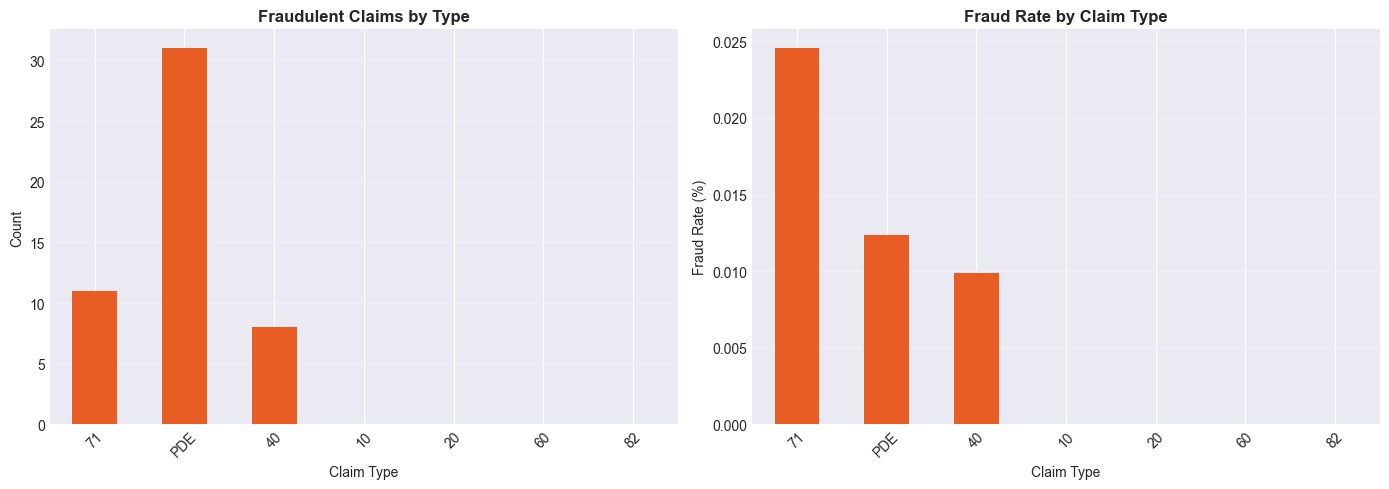

In [27]:
print("="*80)
print("FRAUD BY CLAIM TYPE")
print("="*80)

claim_fraud = df.groupby('claim_type')['is_fraud'].agg(['sum', 'count', 'mean'])
claim_fraud.columns = ['fraudulent_count', 'total_count', 'fraud_rate']
claim_fraud = claim_fraud.sort_values('fraud_rate', ascending=False)

print(f'\n{claim_fraud.to_string()}')

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Count of fraudulent by type
claim_fraud['fraudulent_count'].plot(kind='bar', ax=ax1, color=colors['fraudulent'])
ax1.set_title('Fraudulent Claims by Type', fontsize=12, fontweight='bold')
ax1.set_xlabel('Claim Type')
ax1.set_ylabel('Count')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
ax1.grid(axis='y', alpha=0.3)

# Plot 2: Fraud rate by type
claim_fraud['fraud_rate'].plot(kind='bar', ax=ax2, color=colors['fraudulent'])
ax2.set_title('Fraud Rate by Claim Type', fontsize=12, fontweight='bold')
ax2.set_xlabel('Claim Type')
ax2.set_ylabel('Fraud Rate (%)')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 6: Correlation Analysis with Fraud

CORRELATION WITH FRAUD

Calculating correlations for 20 numeric features...

Top 10 features correlated with fraud:
Feature                                   Correlation
-------------------------------------------------------
total_line_items                               0.0565
line_eligible_total                            0.0439
line_benefit_total                             0.0355
service_category_count                         0.0228
avg_payment_per_line                           0.0209
num_procedure_codes                            0.0198
line_submitted_total                           0.0155
avg_charge_per_line                            0.0104
line_priorpayer_total                         -0.0100
payment_amount                                 0.0095


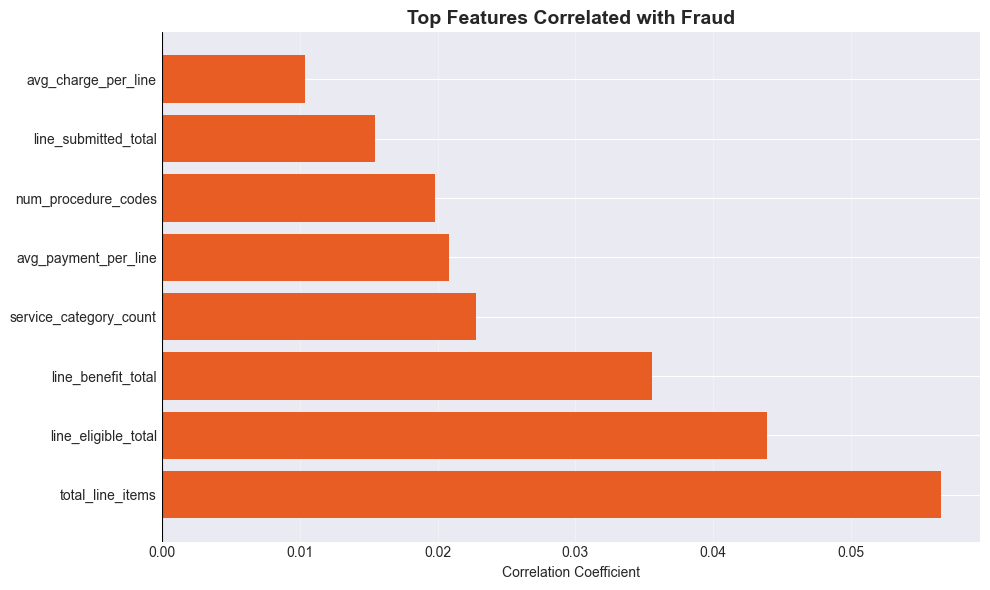

In [28]:
print("="*80)
print("CORRELATION WITH FRAUD")
print("="*80)

numeric_cols = df.select_dtypes(include=['number']).columns
print(f'\nCalculating correlations for {len(numeric_cols) - 1} numeric features...')

correlations = {}
for col in numeric_cols:
    if col != 'is_fraud':
        corr = df[col].corr(df['is_fraud'])
        if not np.isnan(corr):
            correlations[col] = corr

# Sort by absolute correlation
sorted_corr = sorted(correlations.items(), key=lambda x: abs(x[1]), reverse=True)

print(f'\nTop 10 features correlated with fraud:')
print(f'{"Feature":<40} {"Correlation":>12}')
print("-" * 55)

for col, corr in sorted_corr[:10]:
    print(f'{col:<40} {corr:>12.4f}')

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
top_corr = dict(sorted_corr[:8])
colors_bar = [colors['fraudulent'] if v > 0 else '#3B8BD4' for v in top_corr.values()]
ax.barh(list(top_corr.keys()), list(top_corr.values()), color=colors_bar)
ax.set_title('Top Features Correlated with Fraud', fontsize=14, fontweight='bold')
ax.set_xlabel('Correlation Coefficient')
ax.axvline(0, color='black', linestyle='-', linewidth=0.8)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## Step 7: Statistical Significance Testing (T-Tests)

In [29]:
print("="*80)
print("STATISTICAL COMPARISON (T-TESTS)")
print("="*80)

print(f'\nComparing fraudulent vs legitimate claims using independent t-tests:')
print(f'H0: Fraudulent and legitimate claims have equal means')
print(f'Significance level: α = 0.05\n')

test_cols = ['payment_amount', 'total_charged', 'line_deductible_total']

for col in test_cols:
    if col in df.columns:
        legit_vals = legitimate[col].dropna()
        fraud_vals = fraudulent[col].dropna()
        
        t_stat, p_value = stats.ttest_ind(fraud_vals, legit_vals)
        
        print(f'\n{col}:')
        print(f'  Legitimate Mean: ${legit_vals.mean():>12,.2f}')
        print(f'  Fraudulent Mean: ${fraud_vals.mean():>12,.2f}')
        print(f'  T-statistic: {t_stat:>12.4f}')
        print(f'  P-value: {p_value:>12.6f}')
        
        if p_value < 0.05:
            print(f'  Result: SIGNIFICANT DIFFERENCE (reject H0) ✓')
        else:
            print(f'  Result: NO SIGNIFICANT DIFFERENCE (fail to reject H0)')

STATISTICAL COMPARISON (T-TESTS)

Comparing fraudulent vs legitimate claims using independent t-tests:
H0: Fraudulent and legitimate claims have equal means
Significance level: α = 0.05


payment_amount:
  Legitimate Mean: $    2,212.62
  Fraudulent Mean: $    2,712.14
  T-statistic:       0.3671
  P-value:     0.713603
  Result: NO SIGNIFICANT DIFFERENCE (fail to reject H0)

total_charged:
  Legitimate Mean: $      896.64
  Fraudulent Mean: $      885.09
  T-statistic:      -0.0210
  P-value:     0.983257
  Result: NO SIGNIFICANT DIFFERENCE (fail to reject H0)

line_deductible_total:
  Legitimate Mean: $        4.38
  Fraudulent Mean: $        0.00
  T-statistic:      -0.5440
  P-value:     0.586500
  Result: NO SIGNIFICANT DIFFERENCE (fail to reject H0)


## Step 8: Fraud Indicators Explanation

In [30]:
fraud_indicators_info = """
════════════════════════════════════════════════════════════════════════════════
FRAUD INDICATORS USED IN DETECTION
════════════════════════════════════════════════════════════════════════════════

The fraud detection algorithm uses 5 indicators:

1️⃣ HIGH DEDUCTIBLE RATIO (>30% of submitted)
   ─────────────────────────────────────────────────────────────────────────
   What: Deductible > 30% of submitted amount
   Normal Range: 10-20%
   Example: Submitted $100, Deductible $40 → FRAUD INDICATOR!
   Risk: Billing error or intentional fraud

2️⃣ HIGH COINSURANCE RATIO (>50% of benefit)
   ─────────────────────────────────────────────────────────────────────────
   What: Patient coinsurance > 50% of benefit amount
   Normal Range: 10-30%
   Example: Benefit $200, Coinsurance $150 → FRAUD INDICATOR!
   Risk: Claim miscoding or patient abuse

3️⃣ HIGH ADJUSTMENTS (>50% of submitted)
   ─────────────────────────────────────────────────────────────────────────
   What: Adjustments > 50% of submitted amount
   Normal Range: <20%
   Example: Submitted $100, Adjustments $60 → FRAUD INDICATOR!
   Risk: Excessive corrections or claim reversal patterns

4️⃣ MANY ADJUDICATIONS (>10 line items adjusted)
   ─────────────────────────────────────────────────────────────────────────
   What: More than 10 line items need adjustments on single claim
   Normal Range: 0-5 items
   Example: 15 items adjusted out of 20 → FRAUD INDICATOR!
   Risk: Suspicious claim processing patterns

5️⃣ EXTREME BENEFIT AMOUNTS (>95th percentile)
   ─────────────────────────────────────────────────────────────────────────
   What: Benefit amount exceeds 95th percentile
   Normal Range: <$7,000 (median: $200)
   Example: Benefit $10,000 while median $200 → FRAUD INDICATOR!
   Risk: Inflated or fraudulent claim amounts

════════════════════════════════════════════════════════════════════════════════
CLASSIFICATION RULE
════════════════════════════════════════════════════════════════════════════════

Fraud Score = Count of triggered indicators (0-5)

THRESHOLD: Score >= 2 → FRAUDULENT
           Score < 2  → LEGITIMATE

Examples:
  Score 0: Clean claim → ✓ Legitimate
  Score 1: One issue, may be acceptable → ✓ Legitimate
  Score 2: Multiple concerns → ⚠️ FRAUDULENT
  Score 3+: Highly suspicious → ⚠️ FRAUDULENT
════════════════════════════════════════════════════════════════════════════════
"""

print(fraud_indicators_info)


════════════════════════════════════════════════════════════════════════════════
FRAUD INDICATORS USED IN DETECTION
════════════════════════════════════════════════════════════════════════════════

The fraud detection algorithm uses 5 indicators:

1️⃣ HIGH DEDUCTIBLE RATIO (>30% of submitted)
   ─────────────────────────────────────────────────────────────────────────
   What: Deductible > 30% of submitted amount
   Normal Range: 10-20%
   Example: Submitted $100, Deductible $40 → FRAUD INDICATOR!
   Risk: Billing error or intentional fraud

2️⃣ HIGH COINSURANCE RATIO (>50% of benefit)
   ─────────────────────────────────────────────────────────────────────────
   What: Patient coinsurance > 50% of benefit amount
   Normal Range: 10-30%
   Example: Benefit $200, Coinsurance $150 → FRAUD INDICATOR!
   Risk: Claim miscoding or patient abuse

3️⃣ HIGH ADJUSTMENTS (>50% of submitted)
   ─────────────────────────────────────────────────────────────────────────
   What: Adjustments > 50% of

## Step 9: Fraudulent Claims Breakdown

In [31]:
print("="*80)
print("FRAUDULENT CLAIMS BREAKDOWN")
print("="*80)

if len(fraudulent) > 0:
    print(f'\nTotal fraudulent claims: {len(fraudulent)}')
    print(f'\nSample of fraudulent claims (first 10):')
    
    sample_cols = ['claim_type', 'total_charged', 'payment_amount', 
                   'line_deductible_total', 'line_coinsurance_total', 'is_fraud']
    sample_cols = [col for col in sample_cols if col in df.columns]
    
    print(fraudulent[sample_cols].head(10).to_string())
    
    print(f'\nFraudulent claims by claim type:')
    if 'claim_type' in fraudulent.columns:
        print(fraudulent['claim_type'].value_counts())
else:
    print('No fraudulent claims in dataset')

FRAUDULENT CLAIMS BREAKDOWN

Total fraudulent claims: 50

Sample of fraudulent claims (first 10):
    claim_type  total_charged  payment_amount  line_deductible_total  line_coinsurance_total  is_fraud
7          PDE          44.17             NaN                    0.0                  222.55         1
15         PDE          29.81             NaN                    0.0                    0.00         1
18         PDE         260.78             NaN                    0.0                  233.00         1
20          71           0.00         1130.01                    0.0                 1130.01         1
22          71           0.00         1130.01                    0.0                 1130.01         1
24         PDE         432.96             NaN                    0.0                  633.48         1
25         PDE         432.96             NaN                    0.0                  633.48         1
26         PDE         432.96             NaN                    0.0          

## Step 10: Comprehensive Visualization Dashboard

✓ Saved: fraud_analysis_visualization.png


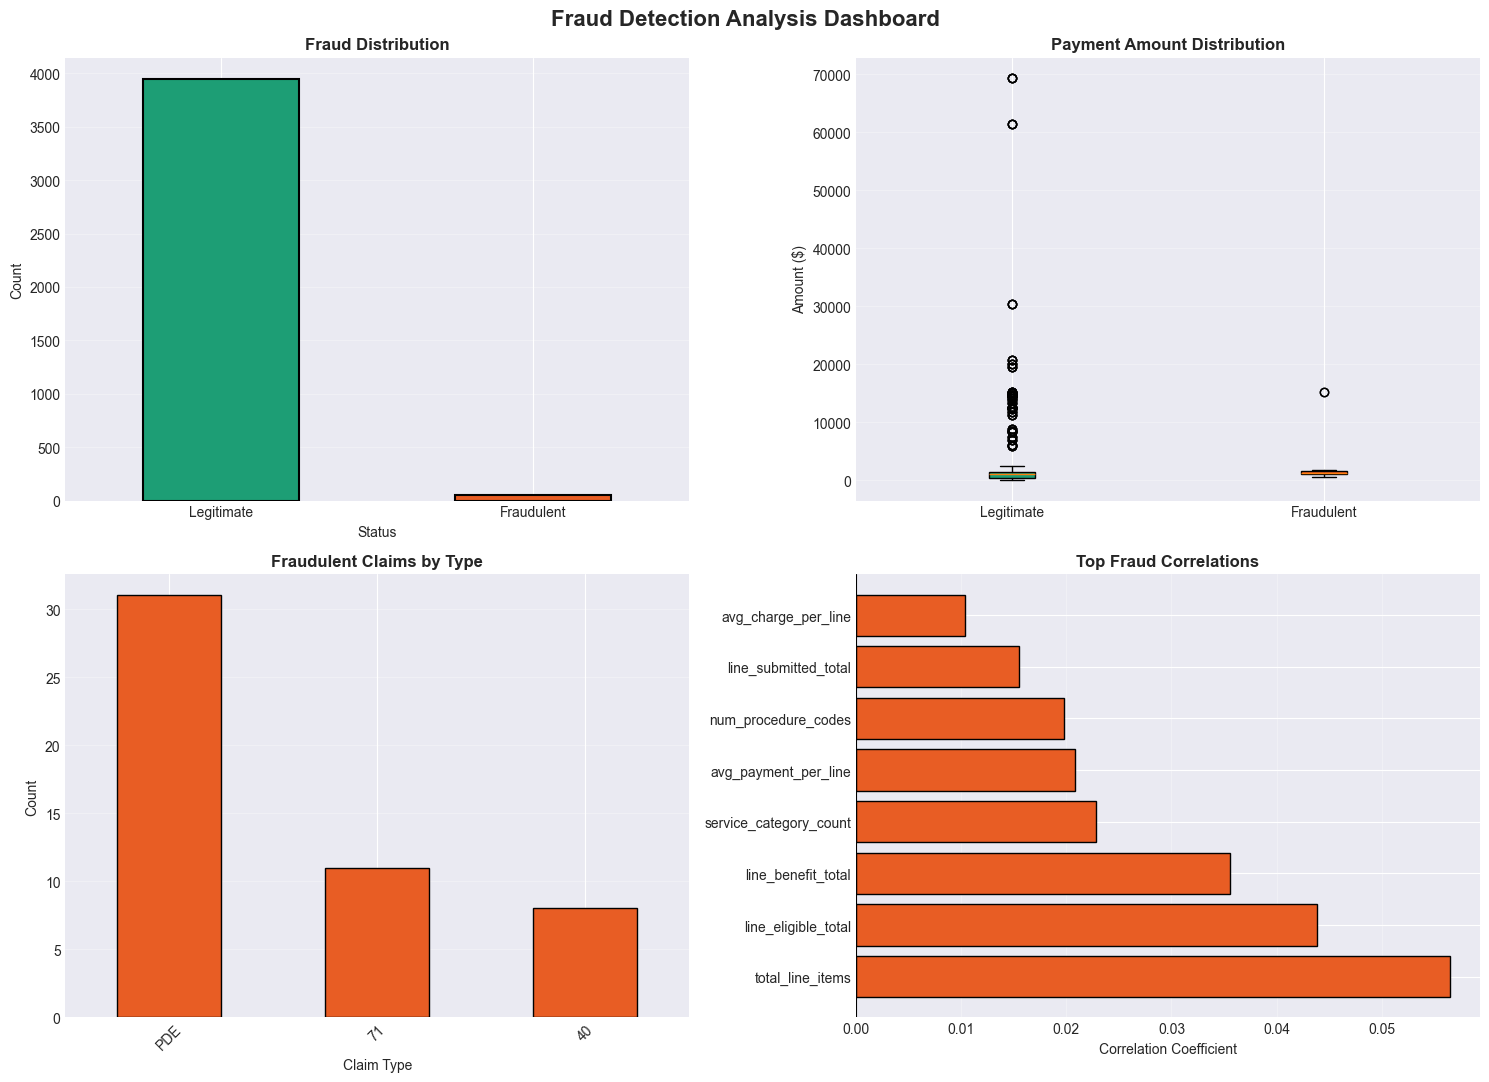

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Fraud Detection Analysis Dashboard', fontsize=16, fontweight='bold')

# Plot 1: Fraud distribution
ax1 = axes[0, 0]
fraud_counts.plot(kind='bar', ax=ax1, color=[colors['legitimate'], colors['fraudulent']],
                  edgecolor='black', linewidth=1.5)
ax1.set_title('Fraud Distribution', fontsize=12, fontweight='bold')
ax1.set_xlabel('Status')
ax1.set_ylabel('Count')
ax1.set_xticklabels(['Legitimate', 'Fraudulent'], rotation=0)
ax1.grid(axis='y', alpha=0.3)

# Plot 2: Payment amount distribution
ax2 = axes[0, 1]
data_to_plot = [legitimate['payment_amount'].dropna(), fraudulent['payment_amount'].dropna()]
bp = ax2.boxplot(data_to_plot, labels=['Legitimate', 'Fraudulent'], patch_artist=True)
for patch, color in zip(bp['boxes'], [colors['legitimate'], colors['fraudulent']]):
    patch.set_facecolor(color)
ax2.set_title('Payment Amount Distribution', fontsize=12, fontweight='bold')
ax2.set_ylabel('Amount ($)')
ax2.grid(axis='y', alpha=0.3)

# Plot 3: Fraudulent claims by type
ax3 = axes[1, 0]
claim_type_fraud = df[df['is_fraud'] == 1]['claim_type'].value_counts()
if len(claim_type_fraud) > 0:
    claim_type_fraud.plot(kind='bar', ax=ax3, color=colors['fraudulent'], edgecolor='black')
    ax3.set_title('Fraudulent Claims by Type', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Claim Type')
    ax3.set_ylabel('Count')
    ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45)
    ax3.grid(axis='y', alpha=0.3)

# Plot 4: Feature correlation
ax4 = axes[1, 1]
top_corr = dict(sorted_corr[:8])
colors_bar = [colors['fraudulent'] if v > 0 else '#3B8BD4' for v in top_corr.values()]
ax4.barh(list(top_corr.keys()), list(top_corr.values()), color=colors_bar, edgecolor='black')
ax4.set_title('Top Fraud Correlations', fontsize=12, fontweight='bold')
ax4.set_xlabel('Correlation Coefficient')
ax4.axvline(0, color='black', linestyle='-', linewidth=0.8)
ax4.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('fraud_analysis_visualization.png', dpi=150, bbox_inches='tight')
print('✓ Saved: fraud_analysis_visualization.png')
plt.show()

## Step 11: Export Detailed Data Files

In [33]:
# Export fraudulent claims details
fraudulent_export = fraudulent[[col for col in 
    ['secure_patient_id', 'claim_type', 'total_charged', 'payment_amount', 
     'line_deductible_total', 'line_coinsurance_total', 'is_fraud'] 
    if col in df.columns]].copy()

fraudulent_export.to_csv('fraudulent_claims_details.csv', index=False)
print(f'✓ Saved fraudulent claims: fraudulent_claims_details.csv')
print(f'  Records: {len(fraudulent_export)}')
print(f'  Columns: {list(fraudulent_export.columns)}')

# Export legitimate claims sample
legitimate_sample = legitimate.sample(min(100, len(legitimate)))[[
    col for col in ['secure_patient_id', 'claim_type', 'total_charged', 'payment_amount', 'is_fraud'] 
    if col in df.columns
]].copy()

legitimate_sample.to_csv('legitimate_claims_sample.csv', index=False)
print(f'\n✓ Saved legitimate sample: legitimate_claims_sample.csv')
print(f'  Records: {len(legitimate_sample)}')
print(f'  Columns: {list(legitimate_sample.columns)}')

print(f'\n✅ DETAILED ANALYSIS COMPLETE!')
print(f'\nGenerated files:')
print(f'  1. fraud_analysis_visualization.png - Charts and dashboards')
print(f'  2. fraud_analysis_report.txt - Statistical report')
print(f'  3. fraudulent_claims_details.csv - Fraudulent claims for review')
print(f'  4. legitimate_claims_sample.csv - Sample of legitimate claims')

✓ Saved fraudulent claims: fraudulent_claims_details.csv
  Records: 50
  Columns: ['secure_patient_id', 'claim_type', 'total_charged', 'payment_amount', 'line_deductible_total', 'line_coinsurance_total', 'is_fraud']

✓ Saved legitimate sample: legitimate_claims_sample.csv
  Records: 100
  Columns: ['secure_patient_id', 'claim_type', 'total_charged', 'payment_amount', 'is_fraud']

✅ DETAILED ANALYSIS COMPLETE!

Generated files:
  1. fraud_analysis_visualization.png - Charts and dashboards
  2. fraud_analysis_report.txt - Statistical report
  3. fraudulent_claims_details.csv - Fraudulent claims for review
  4. legitimate_claims_sample.csv - Sample of legitimate claims


## Step 12: Machine Learning Model Comparison

Train and compare three classifiers on the fraud detection task:
- **Logistic Regression** (linear baseline — the standard linear model for binary classification)
- **Random Forest** (bagging ensemble)
- **XGBoost** (gradient-boosted trees)

Evaluation metrics: Accuracy, Precision, Recall, F1-score, and ROC-AUC.

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('⚠️ xgboost not installed — run: pip install xgboost')

# Build feature matrix: numeric columns only, drop target
numeric_features = df.select_dtypes(include=['number']).columns.tolist()
numeric_features.remove('is_fraud')

X = df[numeric_features].fillna(0).astype(float)
y = df['is_fraud'].astype(int)

print(f'Feature matrix: {X.shape}')
print(f'Target distribution: {dict(y.value_counts())}')
print(f'Features used ({len(numeric_features)}): {numeric_features}')

# Stratified split preserves the fraud ratio in train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Logistic Regression is sensitive to feature scale — standardize
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'\nTrain size: {X_train.shape[0]} (fraud: {y_train.sum()})')
print(f'Test size:  {X_test.shape[0]} (fraud: {y_test.sum()})')

Feature matrix: (4000, 20)
Target distribution: {0: 3950, 1: 50}
Features used (20): ['payment_amount', 'total_charged', 'total_line_items', 'num_diagnosis_codes', 'num_procedure_codes', 'service_category_count', 'modifier_count', 'coverage_reference_count', 'avg_payment_per_line', 'avg_charge_per_line', 'line_submitted_total', 'line_eligible_total', 'line_benefit_total', 'line_paid_to_provider_total', 'line_paid_to_patient_total', 'line_deductible_total', 'line_coinsurance_total', 'line_priorpayer_total', 'line_all_adjudication_total', 'service_duration_days']

Train size: 3000 (fraud: 38)
Test size:  1000 (fraud: 12)


In [35]:
# ─── Model 1: Logistic Regression (linear classifier) ───
print("="*80)
print("LOGISTIC REGRESSION")
print("="*80)

lr_model = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)
lr_proba = lr_model.predict_proba(X_test_scaled)[:, 1]

lr_metrics = {
    'Model': 'Logistic Regression',
    'Accuracy':  accuracy_score(y_test, lr_pred),
    'Precision': precision_score(y_test, lr_pred, zero_division=0),
    'Recall':    recall_score(y_test, lr_pred, zero_division=0),
    'F1':        f1_score(y_test, lr_pred, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_test, lr_proba),
}

for k, v in lr_metrics.items():
    if k != 'Model':
        print(f'  {k:<10}: {v:.4f}')

print(f'\nConfusion Matrix:')
print(confusion_matrix(y_test, lr_pred))
print(f'\nClassification Report:')
print(classification_report(y_test, lr_pred, zero_division=0))

LOGISTIC REGRESSION
  Accuracy  : 0.5630
  Precision : 0.0246
  Recall    : 0.9167
  F1        : 0.0479
  ROC-AUC   : 0.7432

Confusion Matrix:
[[552 436]
 [  1  11]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.56      0.72       988
           1       0.02      0.92      0.05        12

    accuracy                           0.56      1000
   macro avg       0.51      0.74      0.38      1000
weighted avg       0.99      0.56      0.71      1000



In [36]:
# --- Model 2: Random Forest (bagging ensemble) ---
print("="*80)
print("RANDOM FOREST")
print("="*80)

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

rf_metrics = {
    'Model': 'Random Forest',
    'Accuracy':  accuracy_score(y_test, rf_pred),
    'Precision': precision_score(y_test, rf_pred, zero_division=0),
    'Recall':    recall_score(y_test, rf_pred, zero_division=0),
    'F1':        f1_score(y_test, rf_pred, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_test, rf_proba),
}

for k, v in rf_metrics.items():
    if k != 'Model':
        print(f'  {k:<10}: {v:.4f}')

print(f'\nConfusion Matrix:')
print(confusion_matrix(y_test, rf_pred))
print(f'\nClassification Report:')
print(classification_report(y_test, rf_pred, zero_division=0))

RANDOM FOREST
  Accuracy  : 0.9390
  Precision : 0.0984
  Recall    : 0.5000
  F1        : 0.1644
  ROC-AUC   : 0.7392

Confusion Matrix:
[[933  55]
 [  6   6]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.97       988
           1       0.10      0.50      0.16        12

    accuracy                           0.94      1000
   macro avg       0.55      0.72      0.57      1000
weighted avg       0.98      0.94      0.96      1000



In [37]:
# --- Model 3: XGBoost (gradient boosting ensemble) ---
print("="*80)
print("XGBOOST")
print("="*80)

if HAS_XGB:
    neg = (y_train == 0).sum()
    pos = (y_train == 1).sum()
    scale_pos_weight = neg / pos if pos > 0 else 1.0

    xgb_model = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=scale_pos_weight,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1,
    )
    xgb_model.fit(X_train, y_train)

    xgb_pred = xgb_model.predict(X_test)
    xgb_proba = xgb_model.predict_proba(X_test)[:, 1]

    xgb_metrics = {
        'Model': 'XGBoost',
        'Accuracy':  accuracy_score(y_test, xgb_pred),
        'Precision': precision_score(y_test, xgb_pred, zero_division=0),
        'Recall':    recall_score(y_test, xgb_pred, zero_division=0),
        'F1':        f1_score(y_test, xgb_pred, zero_division=0),
        'ROC-AUC':   roc_auc_score(y_test, xgb_proba),
    }

    for k, v in xgb_metrics.items():
        if k != 'Model':
            print(f'  {k:<10}: {v:.4f}')

    print(f'\nConfusion Matrix:')
    print(confusion_matrix(y_test, xgb_pred))
    print(f'\nClassification Report:')
    print(classification_report(y_test, xgb_pred, zero_division=0))
else:
    print('xgboost not installed - skipping. Install with: pip install xgboost')
    xgb_model = None
    xgb_pred = None
    xgb_proba = None
    xgb_metrics = None

XGBOOST
  Accuracy  : 0.9270
  Precision : 0.0822
  Recall    : 0.5000
  F1        : 0.1412
  ROC-AUC   : 0.7780

Confusion Matrix:
[[921  67]
 [  6   6]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.93      0.96       988
           1       0.08      0.50      0.14        12

    accuracy                           0.93      1000
   macro avg       0.54      0.72      0.55      1000
weighted avg       0.98      0.93      0.95      1000



In [38]:
# --- Model 4: Isolation Forest (unsupervised anomaly detection / QML-style) ---
from sklearn.ensemble import IsolationForest

print("="*80)
print("ISOLATION FOREST (Anomaly Detection)")
print("="*80)

# Train on legitimate-only rows so it learns "normal" behaviour
X_train_legit = X_train[y_train == 0]
contamination = max((y_train == 1).mean(), 0.01)

iso_model = IsolationForest(
    n_estimators=200,
    contamination=contamination,
    random_state=42,
    n_jobs=-1,
)
iso_model.fit(X_train_legit)

# predict(): 1 = inlier (legit), -1 = outlier (fraud)
iso_raw = iso_model.predict(X_test)
iso_pred = (iso_raw == -1).astype(int)
# Higher score = more anomalous = more likely fraud
iso_score = -iso_model.decision_function(X_test)

iso_metrics = {
    'Model': 'Isolation Forest',
    'Accuracy':  accuracy_score(y_test, iso_pred),
    'Precision': precision_score(y_test, iso_pred, zero_division=0),
    'Recall':    recall_score(y_test, iso_pred, zero_division=0),
    'F1':        f1_score(y_test, iso_pred, zero_division=0),
    'ROC-AUC':   roc_auc_score(y_test, iso_score),
}

for k, v in iso_metrics.items():
    if k != 'Model':
        print(f'  {k:<10}: {v:.4f}')

print(f'\nConfusion Matrix:')
print(confusion_matrix(y_test, iso_pred))
print(f'\nClassification Report:')
print(classification_report(y_test, iso_pred, zero_division=0))

ISOLATION FOREST (Anomaly Detection)


  Accuracy  : 0.9810
  Precision : 0.1111
  Recall    : 0.0833
  F1        : 0.0952
  ROC-AUC   : 0.4741

Confusion Matrix:
[[980   8]
 [ 11   1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       988
           1       0.11      0.08      0.10        12

    accuracy                           0.98      1000
   macro avg       0.55      0.54      0.54      1000
weighted avg       0.98      0.98      0.98      1000



## Step 13: Model Comparison Plot

Compare Logistic Regression, Random Forest, XGBoost, and Isolation Forest (QML-style anomaly detection) with metrics bar chart, ROC curves, and confusion matrices. Saved to model_comparison.png.


MODEL COMPARISON
                     Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                            
Logistic Regression     0.563     0.0246  0.9167  0.0479   0.7432
Random Forest           0.939     0.0984  0.5000  0.1644   0.7392
XGBoost                 0.927     0.0822  0.5000  0.1412   0.7780
Isolation Forest        0.981     0.1111  0.0833  0.0952   0.4741

Plot saved to: model_comparison.png


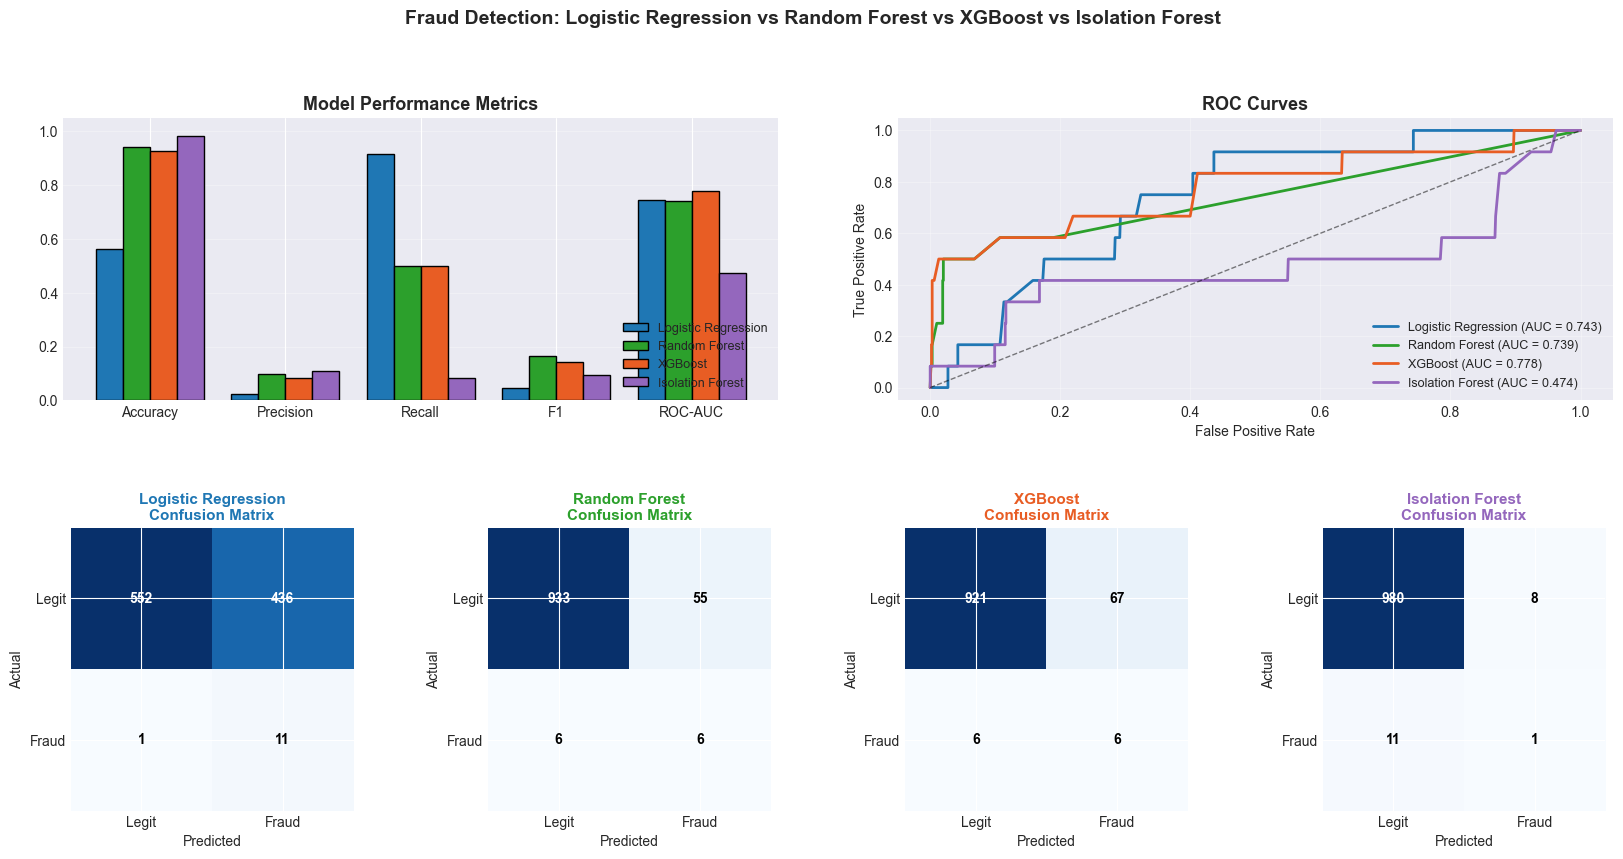

In [39]:
# --- Compare all four models: metrics bar chart, ROC curves, confusion matrices ---
from sklearn.metrics import roc_curve

all_metrics = [lr_metrics, rf_metrics]
preds_probas = [
    ('Logistic Regression', lr_pred, lr_proba, '#1f77b4'),
    ('Random Forest',       rf_pred, rf_proba, '#2ca02c'),
]
if HAS_XGB and xgb_metrics is not None:
    all_metrics.append(xgb_metrics)
    preds_probas.append(('XGBoost', xgb_pred, xgb_proba, '#E85D24'))

all_metrics.append(iso_metrics)
preds_probas.append(('Isolation Forest', iso_pred, iso_score, '#9467bd'))

results_df = pd.DataFrame(all_metrics).set_index('Model')
print("\n" + "="*80)
print("MODEL COMPARISON")
print("="*80)
print(results_df.round(4).to_string())

n_models = len(preds_probas)
fig = plt.figure(figsize=(5 * n_models, 9))
gs = fig.add_gridspec(2, n_models, hspace=0.45, wspace=0.4)

# Top-left: metric bar chart across models
ax_bar = fig.add_subplot(gs[0, :max(2, n_models // 2)])
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']
x_pos = np.arange(len(metric_names))
bar_w = 0.8 / n_models
for i, (name, _, _, color) in enumerate(preds_probas):
    vals = [results_df.loc[name, m] for m in metric_names]
    ax_bar.bar(x_pos + i * bar_w, vals, bar_w, label=name, color=color, edgecolor='black')
ax_bar.set_xticks(x_pos + bar_w * (n_models - 1) / 2)
ax_bar.set_xticklabels(metric_names)
ax_bar.set_ylim(0, 1.05)
ax_bar.set_title('Model Performance Metrics', fontsize=13, fontweight='bold')
ax_bar.legend(loc='lower right', fontsize=9)
ax_bar.grid(axis='y', alpha=0.3)

# Top-right: ROC curves
ax_roc = fig.add_subplot(gs[0, max(2, n_models // 2):])
for name, _, proba, color in preds_probas:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = results_df.loc[name, 'ROC-AUC']
    ax_roc.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC = {auc:.3f})')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
ax_roc.set_xlabel('False Positive Rate')
ax_roc.set_ylabel('True Positive Rate')
ax_roc.set_title('ROC Curves', fontsize=13, fontweight='bold')
ax_roc.legend(loc='lower right', fontsize=9)
ax_roc.grid(alpha=0.3)

# Bottom row: per-model confusion matrices
for i, (name, pred, _, color) in enumerate(preds_probas):
    ax_cm = fig.add_subplot(gs[1, i])
    cm = confusion_matrix(y_test, pred)
    im = ax_cm.imshow(cm, cmap='Blues')
    for r in range(cm.shape[0]):
        for c in range(cm.shape[1]):
            ax_cm.text(c, r, f'{cm[r, c]:,}', ha='center', va='center',
                       color='white' if cm[r, c] > cm.max() / 2 else 'black',
                       fontweight='bold')
    ax_cm.set_xticks([0, 1]); ax_cm.set_xticklabels(['Legit', 'Fraud'])
    ax_cm.set_yticks([0, 1]); ax_cm.set_yticklabels(['Legit', 'Fraud'])
    ax_cm.set_xlabel('Predicted'); ax_cm.set_ylabel('Actual')
    ax_cm.set_title(f'{name}\nConfusion Matrix', fontsize=11, fontweight='bold', color=color)

plt.suptitle('Fraud Detection: Logistic Regression vs Random Forest vs XGBoost vs Isolation Forest',
             fontsize=14, fontweight='bold', y=1.00)
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
print("\nPlot saved to: model_comparison.png")
plt.show()
